# Lab 03: acquire small scientific inputs and explain failures

Automated Workflows in Satellite Image Processing · v1.0 · 15 October 2026

Lab 02 discovered catalogue items and stored one preview. This lab acquires the red
and near-infrared bands needed for NDVI, but stores only a small area of interest.
You design the new database tables completely and then use the resulting archive
to investigate failures.

Use this notebook for predictions, SQL inspection and explanations. Edit
`student_schema.sql` in your editor. Run acquisition and failure cases in a terminal.
The supplied Python is working code, not a new function-repair exercise.

Deliverables: your full schema SQL, your diagnostic SQL, this notebook with evidence
and explanations, and a small final JSON report. Core work: approximately two hours.


## 1. Setup and continuity

Read README.md for installation. From a terminal in this folder, install Rasterio,
NumPy, Matplotlib and Jupyter into your existing environment if needed:

```bash
conda install -c conda-forge "rasterio>=1.4,<2" numpy matplotlib jupyterlab ipykernel
```

We preserve Lab 02's streams, scenes, downloads, runs and stream_scenes tables. You
can copy your database with --from-lab2 on the first init; README.md gives the command.
The default path creates a separate Lab 03 archive and uses captured actual Lab 01
metadata. The original Lab 02 database is never edited by the copy operation.

The fixed example is from June 2025. It is chosen for reproducibility, not presented
as the newest acquisition. Live acquire commands always read remote COG data;
packaged real subsets are used only by offline checks.

### Completed explanation

This exercise uses the default separate Lab 03 archive seeded with 16 actual
captured June 2025 catalogue records. The historical pinned item is outside the
Lab 02 September–October interval, so no Lab 02 database copy was needed. This
choice keeps the existing weekly experiment unchanged. The seeded metadata is
not described as a new live discovery; all scientific subset acquisitions below
used actual remote COG range responses.

Execution used Python 3.12.14 with Rasterio 1.5.2, NumPy 2.5.4 and Matplotlib
3.11.2. The supplied application, raster reader, range reader and checks remain
unchanged. The original comment-only student schema failed on all five missing
tables; the completed schema passes all eight supplied check groups.


In [1]:
from pathlib import Path
import json
import sqlite3
import subprocess
import sys

PROJECT = Path.cwd().resolve()
assert (PROJECT / 'lab03_cli.py').is_file(), 'Set PROJECT to the extracted lab folder'

def run_checks():
    result = subprocess.run([sys.executable, str(PROJECT / 'check_lab03.py')], cwd=PROJECT, capture_output=True, text=True)
    print(result.stdout)
    if result.stderr:
        print(result.stderr)
    print('Exit code:', result.returncode)
    return result.returncode

print('Project:', PROJECT)

# Captured terminal and SQL evidence is read only; no acquisition runs here.
import re

def read_evidence(label):
    path = PROJECT / 'state' / 'evidence' / f'{label}.json'
    if not path.is_file():
        print(label, ': local snapshot absent; consult saved notebook outputs.')
        return None
    return json.loads(path.read_text())

def show_terminal(label):
    record = read_evidence(label)
    if record is None:
        return
    print('Command:', ' '.join(record['command'][1:]))
    print('Exit code:', record['exit_code'])
    print(record['stdout'])

def show_query(snapshot, name):
    record = read_evidence(snapshot)
    if record is None:
        return
    print('Snapshot:', snapshot, '| Captured:', record['captured_at'])
    print('Query:', name)
    print(json.dumps(record['query_results'][name], indent=2))

query_sql = {name: sql.strip() for name, sql in re.findall(
    r'-- query: (\w+)\n(.*?)(?=-- query: |\Z)',
    (PROJECT / 'investigation_queries.sql').read_text(), re.S)}


Project: /Users/molczane/Developer/Automated_Workflows/Labs/Lab03


## 2. Design five complete tables (45–60 minutes)

Read SCHEMA_CONTRACT.md. Write every CREATE TABLE statement yourself in
student_schema.sql. The file initially contains only comments. Required column
names let the supplied service use your schema, but there are no partial table
statements to complete.

Before writing SQL, sketch these relationships and explain the expected cardinality:

| Parent | Child | Question |
|---|---|---|
| scenes | assets | Can one scene have more than one band or metadata revision? |
| assets | subset_requests | Can the same band be stored for two AOIs? |
| subset_requests | download_attempts | Can a request fail and later succeed? |
| runs | download_attempts | Can one invocation attempt more than one band? |
| download_attempts | artifacts | Which attempt first registered these exact bytes? |
| artifacts | artifact_locations | Can a stored file disappear without erasing the artifact's identity? |

Also record each request's latest artifact and each attempt's result artifact.
Those artifacts must belong to the same request, not simply be any existing ID.
The contract explains the composite references needed for that condition.

Which facts belong to current state, and which must remain as history? Do not
make run_id or subset_id unique in the attempts table. Predict what that would
prevent during recovery.

### Completed explanation

Relationship sketch (one row on the left may have zero or many on the right):

```text
scenes 1 ──< assets 1 ──< subset_requests 1 ──< download_attempts >── 1 runs
                                |                    |
                                | 1                  | creator of 0..many
                                v                    v
                             artifacts >─────────────┘
                                | 1
                                v
                         artifact_locations (0..many)
```

Each asset belongs to exactly one scene; red and nir and later metadata revisions
are separate assets. Each subset belongs to one asset revision and one AOI/recipe
combination. Each attempt belongs to one request and one invocation; a request
can fail and later succeed, and a run can attempt both bands. Each artifact records
exactly one creating attempt; this workflow creates at most one new artifact per
successful transfer attempt, while later attempts may reproduce or reuse it.
One artifact can have multiple locations, and a location can become unavailable
without erasing the identity of previously stored bytes.

A request optionally points to its latest artifact, and an attempt optionally
points to the artifact it produced or inspected. These are composite references
including subset_id, so a red file from another AOI cannot satisfy the link.
Request and location statuses describe current state. Attempt rows and artifact
creation records preserve history. Making run_id unique in attempts would reject
the second band of a run; making subset_id unique would reject retries and cache
verification. All primary-key IDs explicitly reject NULL, including SQLite TEXT
primary keys.


In [2]:
run_checks()


PASS: five complete table definitions and column contract
PASS: primary keys and scene/asset/request/run foreign keys
PASS: AOI identity, uniqueness and allowed states
PASS: attempt outcomes, timestamps and byte counts
PASS: composite relationships prevent cross-AOI artifact references
PASS: real-file verification, missing/corrupt diagnosis and preserved success history
PASS: real B04/B08 grids, AOI masking, scale/offset and pixel cap
PASS: server ignoring Range is refused without reading its body
All checks used actual captured EO data; no live network requests were made.

attempt=attempt-11d0ca94-683f-41df-8e5a-e1b614585bad code=FILE_MISSING Recorded file is absent: real_red_aoi.tif
attempt=attempt-d4c2001c-b95a-4c75-8fd6-20d782277bd4 code=FILE_CORRUPT Size/hash mismatch for real_red_aoi.tif

Exit code: 0


0

Write your schema explanation here. Identify two uniqueness constraints and two
foreign key constraints, and give a concrete bad record each would reject. Explain
why an asset+band identity alone is insufficient when the AOI changes.

### Completed explanation

Two uniqueness constraints and concrete rejected records:

- `assets(collection,item_id,asset_key,metadata_sha256)` rejects a second asset
  ID for the same red source metadata revision. Changed metadata can be retained
  as another revision rather than overwriting provenance.
- `subset_requests(asset_id,aoi_key,recipe_version)` rejects a second request ID
  for identical source, AOI and recipe. It still permits two different AOIs of
  that source. `artifacts(subset_id,sha256)` similarly prevents duplicate byte
  identities when a retry writes the same output again.

Two foreign-key protections and concrete rejected records:

- The scene reference rejects an asset whose `(collection,item_id)` does not
  identify a stored scene.
- `(latest_artifact_id,subset_id)` rejects pointing the smaller-AOI request to
  the larger-AOI artifact, even when that artifact ID exists. Equivalent paired
  references protect an attempt's result and an artifact's creating attempt.

The explicit UNIQUE parent pairs are required by SQLite for those paired foreign
keys. Nullable artifact links break the insertion cycle: insert a request with
no result, then a running attempt, then the artifact linked to that attempt,
then attach the result and record success. The creator need not already be a
terminal success while its new artifact is being registered in that transaction.

Status CHECKs reject unknown lifecycle values. A ready request and a succeeded
or reused attempt must name an artifact; running attempts have no finish timestamp
and terminal ones must have one. Byte counters are nonnegative integers, stored
sizes are positive integers, and JSON fields must contain valid JSON. Stage stays
non-null diagnostic text, separate from the constrained lifecycle status. Indexes
support request/run history and artifact-location lookups.

An asset already identifies its band, but it says nothing about the AOI crop.
Output identity therefore needs the source revision, AOI geometry/pixel rule and
recipe as well. Database constraints cannot test whether a path exists or whether
its current bytes match the recorded hash: the verifier must actually inspect
the filesystem and raster metadata. Foreign-key enforcement is enabled per
connection; `PRAGMA foreign_key_check` alone cannot verify files.


## 3. Plan before storing scientific data (10 minutes)

Once checks pass, initialize the new archive and inspect the planned size:

```bash
python lab03_cli.py init --config config/krakow_aoi.json
```

```bash
python lab03_cli.py plan --config config/krakow_aoi.json
```

Open config/krakow_aoi.json. Distinguish discovery_bbox, which selects catalogue
candidates, from aoi_bbox, which limits the stored pixels. Both use west, south,
east, north in EPSG:4326. item_id pins one tile; the AOI must fit entirely inside it.

For each band, report source_shape, subset shape, pixel size, CRS, raw pixel bytes,
scale and offset. The supplied default should produce 227 rows by 219 columns at
10 m resolution, much smaller than the 10,980 by 10,980 source tile.

Use the alternative too_large_aoi.json configuration to investigate a budget failure:

```bash
python lab03_cli.py plan --config config/too_large_aoi.json
```

That command is expected to fail before remote raster data is read. Explain why a
local disk limit and an HTTP transfer limit are different controls. Reading a COG
window fetches whole source blocks; network bytes may exceed stored file bytes.

### Completed explanation

`discovery_bbox` selects catalogue candidates; `aoi_bbox` defines retained pixels
inside the pinned tile. Neither implies that an intersecting scene is already
cropped. The AOI is transformed from EPSG:4326 into the native UTM grid, rounded
outward, then masked by pixel-center inclusion. No reprojection or resampling is
performed between red and nir; their grids must match.

| Band | Source shape | Subset shape | Pixel size | CRS | Raw bytes | Scale | Offset |
|---|---|---|---|---|---:|---:|---:|
| red | 10980 × 10980 | 227 × 219 | 10 × 10 m | EPSG:32634 | 99,426 | 0.0001 | -0.1 |
| nir | 10980 × 10980 | 227 × 219 | 10 × 10 m | EPSG:32634 | 99,426 | 0.0001 | -0.1 |

The main source window is column 2198, row 5416, width 219, height 227. Nodata is
0 and the native uint16 values, calibration and georeferencing are preserved.
The pair's raw pixel estimate is 198,852 bytes, excluding
GeoTIFF headers and compression.

The too-large AOI plan returned exit 1 with “AOI window is empty or exceeds the
pixel budget” before any remote raster bytes were read. It did not create an
acquisition attempt. The 500,000-pixel-per-band limit bounds output work, while
8 MiB per output and 150 MiB per workspace bound disk use. The separate 12 MiB
per-band HTTP limit bounds actual response-body bytes; a small crop can require
whole source blocks and headers, so network bytes can greatly exceed output size.


In [3]:
show_terminal('plan-main')
show_terminal('plan-too-large')


Command: lab03_cli.py plan --config config/krakow_aoi.json
Exit code: 0
{
  "item_id": "S2C_34UDA_20250605_0_L2A",
  "plans": [
    {
      "asset_key": "red",
      "source_url": "https://sentinel-cogs.s3.us-west-2.amazonaws.com/sentinel-s2-l2a-cogs/34/U/DA/2025/6/S2C_34UDA_20250605_0_L2A/B04.tif",
      "crs": "EPSG:32634",
      "source_shape": [
        10980,
        10980
      ],
      "source_transform": [
        10.0,
        0.0,
        399960.0,
        0.0,
        -10.0,
        5600040.0
      ],
      "window": [
        2198,
        5416,
        219,
        227
      ],
      "shape": [
        227,
        219
      ],
      "transform": [
        10.0,
        0.0,
        421940.0,
        0.0,
        -10.0,
        5545880.0
      ],
      "dtype": "uint16",
      "nodata": 0,
      "scale": 0.0001,
      "offset": -0.1,
      "aoi_bbox": [
        19.91,
        50.04,
        19.94,
        50.06
      ],
      "recipe": "native10m-wgs84-mask-v1",
      "raw

## 4. Acquire and repeat (10 minutes plus network time)

```bash
python lab03_cli.py acquire --config config/krakow_aoi.json
```

```bash
python lab03_cli.py acquire --config config/krakow_aoi.json
```

```bash
python lab03_cli.py report --config config/krakow_aoi.json
```

The first run requests two real bands via byte ranges and stores two masked AOI
GeoTIFFs. The second checks their size, SHA-256 and raster metadata and records
reused attempts. Explain why reused is not another transfer and why it is still
worth recording.

Open state/catalogue.sqlite in DB Browser. Inspect the five original tables and
your five new tables. Existing preview downloads remain in downloads; scientific
cutout attempts are in download_attempts and link to subset_requests.

### Completed explanation

The first acquisition succeeded for both bands. Red received
2,097,153 HTTP body bytes and stored
75,490 bytes; nir received
2,097,153 and stored
75,702 bytes. Each recorded last HTTP status was 206.
The repeat recorded two `reused` cache_verify attempts with zero network bytes,
while retaining the same artifact IDs and two original transfer attempts.

Reuse is a new verification operation, not another transfer: the service checks
file existence, size, SHA-256 and raster metadata against the request. Recording
it shows when the archive was last verified and which run used those inputs.
The schema retains the five original tables and adds exactly five new ones.
`downloads` remains the preview table; cropped scientific inputs use
subset_requests, download_attempts, artifacts and artifact_locations.

Paths include both the scene and an AOI-key prefix so different source scenes or
crops do not collide. Full identities remain in SQLite; the shortened filename
cannot prove the parameters, calibration or complete attempt history by itself.


In [4]:
show_terminal('acquire-main')
show_terminal('acquire-repeat')


Command: lab03_cli.py acquire --config config/krakow_aoi.json
Exit code: 0
{
  "run_id": "lab03-59509f9f-c4f3-48ff-b3b2-2c7668adfe09",
  "status": "succeeded",
  "outputs": [
    {
      "subset_id": "5462fd6b1d071487ebf4f9872da69c339ad7568e2b9bd923d7e7ad1e40fb2e2b",
      "artifact_id": "59c9437e300a3549f75913bc0b4eeace6430e4be531fe988dded691a43ee71db",
      "path": "/Users/molczane/Developer/Automated_Workflows/Labs/Lab03/data/S2C_34UDA_20250605_0_L2A/48e7066dc251/red-59c9437e300a3549.tif",
      "outcome": "succeeded",
      "network_bytes": 2097153,
      "saved_bytes": 75490
    },
    {
      "subset_id": "f66f860d150ad4f0a41201bad30d12ab8f99fee60a4d3d25810569c6d44c6f0e",
      "artifact_id": "dcfea4a7d5a3e6efc655301bc757ff7fe2477914191628bd3c8b81aabf39292e",
      "path": "/Users/molczane/Developer/Automated_Workflows/Labs/Lab03/data/S2C_34UDA_20250605_0_L2A/48e7066dc251/nir-dcfea4a7d5a3e6ef.tif",
      "outcome": "succeeded",
      "network_bytes": 2097153,
      "saved_bytes"

### One worked SQL join

Run this in Execute SQL. It follows an attempt to its run, AOI request and source
band. Use it as a starting point for your own diagnostic queries.

```sql
SELECT r.run_id, r.command, a.item_id, a.asset_key,
       s.aoi_key, d.status, d.stage, d.network_bytes,
       d.http_status, d.error_code, d.error_message
FROM download_attempts AS d
JOIN runs AS r ON r.run_id = d.run_id
JOIN subset_requests AS s ON s.subset_id = d.subset_id
JOIN assets AS a ON a.asset_id = s.asset_id
ORDER BY d.started_at, d.attempt_id;
```

Write your own query to show the saved paths, file hashes and latest location
states. Compare HTTP bytes with file sizes. Do not sum bytes after joining a
one-to-many location table unless you account for the duplicated attempt rows.

### Completed explanation

`saved_files` in investigation_queries.sql joins the request's latest artifact to
its full hash, stored size, path and last location state. `transfer_vs_storage`
first aggregates attempts by request and artifacts by request separately, then
joins those totals. It does not sum network bytes after joining file locations,
which could multiply each attempt when an artifact has several paths.

The real main-AOI results below show 2,097,153 transferred bytes for each band,
compared with 75,490 red and 75,702 nir stored bytes. Registered bytes count distinct
artifact versions, not current disk occupancy; actual file existence and sizes
were checked separately. Zero HTTP bytes on a reused attempt does not mean that
no local file was read.


In [5]:
print(query_sql['saved_files'])
show_query('main-after-repeat', 'saved_files')
print(query_sql['transfer_vs_storage'])
show_query('main-after-repeat', 'transfer_vs_storage')


-- Paths, hashes and last verified availability for each request's latest result.
SELECT a.item_id, a.asset_key, s.aoi_key, s.subset_id, f.artifact_id,
       f.sha256, f.size_bytes, l.local_path, l.status AS location_status,
       l.checked_at, f.raster_json
FROM subset_requests AS s
JOIN assets AS a ON a.asset_id = s.asset_id
LEFT JOIN artifacts AS f
    ON f.artifact_id = s.latest_artifact_id AND f.subset_id = s.subset_id
LEFT JOIN artifact_locations AS l ON l.artifact_id = f.artifact_id
ORDER BY a.asset_key, s.aoi_key, l.local_path;
Snapshot: main-after-repeat | Captured: 2026-10-25T16:59:40.629635Z
Query: saved_files
[
  {
    "item_id": "S2C_34UDA_20250605_0_L2A",
    "asset_key": "nir",
    "aoi_key": "48e7066dc2510b10454cbc305c90ecb47f71c0966d733d6ab4ec2630c8745724",
    "subset_id": "f66f860d150ad4f0a41201bad30d12ab8f99fee60a4d3d25810569c6d44c6f0e",
    "artifact_id": "dcfea4a7d5a3e6efc655301bc757ff7fe2477914191628bd3c8b81aabf39292e",
    "sha256": "b8cf04708203ae6ee6a7306f42

In [6]:
DB = PROJECT / 'state' / 'catalogue.sqlite'
if not DB.is_file():
    print('Write/check the schema and run init/acquire in the terminal first.')
else:
    with sqlite3.connect(f'{DB.as_uri()}?mode=ro', uri=True) as conn:
        names = {row[0] for row in conn.execute("SELECT name FROM sqlite_master WHERE type='table'")}
        if 'download_attempts' not in names:
            print('The five new tables have not been initialized yet.')
        else:
            conn.row_factory = sqlite3.Row
            rows = [dict(row) for row in conn.execute('SELECT run_id,status,stage,network_bytes,error_code FROM download_attempts ORDER BY rowid')]
            print(json.dumps(rows, indent=2))


[
  {
    "run_id": "lab03-59509f9f-c4f3-48ff-b3b2-2c7668adfe09",
    "status": "succeeded",
    "stage": "complete",
    "network_bytes": 2097153,
    "error_code": null
  },
  {
    "run_id": "lab03-59509f9f-c4f3-48ff-b3b2-2c7668adfe09",
    "status": "succeeded",
    "stage": "complete",
    "network_bytes": 2097153,
    "error_code": null
  },
  {
    "run_id": "lab03-6885d9d2-0719-4ec8-bb83-dbe824a5005b",
    "status": "reused",
    "stage": "cache_verify",
    "network_bytes": 0,
    "error_code": null
  },
  {
    "run_id": "lab03-6885d9d2-0719-4ec8-bb83-dbe824a5005b",
    "status": "reused",
    "stage": "cache_verify",
    "network_bytes": 0,
    "error_code": null
  },
  {
    "run_id": "lab03-bff0bde6-ae53-42cc-9042-b8a973b56e52",
    "status": "succeeded",
    "stage": "complete",
    "network_bytes": 2097153,
    "error_code": null
  },
  {
    "run_id": "lab03-bff0bde6-ae53-42cc-9042-b8a973b56e52",
    "status": "succeeded",
    "stage": "complete",
    "network_bytes": 2

## 5. Failure case A: one band succeeded, then the connection failed (20 minutes)

Predict the database and file states before running this:

```bash
python lab03_cli.py case --config config/krakow_aoi.json --name network
```

The command creates cases/network/config.json and its own database/data directory,
then deliberately interrupts the nir reader after actual range responses. A
failure exit code is expected. It does not damage the main archive. The connection
failure is controlled; the scene records and imagery are real.

Open cases/network/state/catalogue.sqlite. Before any recovery:

1. Write SQL to identify the failed run, failed band, failure stage and bytes received.
2. Show which band already has an artifact and which has none.
3. Explain why a failed run does not imply that every operation in it failed. How could an INNER JOIN to artifacts hide the failed attempt?
4. Explain why advancing a discovery watermark would not prove a band was stored.

Record evidence, then recover:

```bash
python lab03_cli.py acquire --config cases/network/config.json
```

Show that the red file was verified/reused, the nir operation was retried, and the
original failure remains in the attempts table. Do not overwrite the failed row
to make the history look successful. Finish with a small before/after table of
run, band, attempt status, stage and artifact identity.

### Completed explanation

Prediction recorded before the case: red should finish and remain registered;
nir should fail during its range read without an artifact. Recovery should verify
and reuse red, create a new nir attempt, and preserve the failed nir row.

**Symptom and query.** The generated case returned exit 1 with a controlled range
interruption. `network_history` uses LEFT JOIN artifacts so the failed attempt
with NULL artifact_id stays visible; `request_state` shows which band has a result.
An INNER JOIN would hide precisely the failed nir attempt being investigated.

**Observed before recovery:**

| Run (prefix) | Band | Attempt (prefix) | Status | Stage | HTTP bytes | Artifact (prefix) |
|---|---|---|---|---|---:|---|
| lab03-54292676 | red | attempt-04d40285 | succeeded | complete | 2,097,153 | 59c9437e300a3549 |
| lab03-54292676 | nir | attempt-a485f16e | failed | read_window | 262,145 | NULL |

Nir failed at `read_window` with `RANGE_READ_FAILED` after
262,145 actual HTTP body bytes and last status 206;
it had no artifact. Red was already complete and available. A run is an aggregate
outcome: one operation can fail after another has committed valid output.
The discovery watermark only describes catalogue coverage, not stored band bytes.

**Recovery.** `acquire --config cases/network/config.json` completed successfully.
The new attempts were:

| Run (prefix) | Band | Attempt (prefix) | Status | Stage | HTTP bytes | Artifact (prefix) |
|---|---|---|---|---|---:|---|
| lab03-227b7ea5 | red | attempt-5056a1c6 | reused | cache_verify | 0 | 59c9437e300a3549 |
| lab03-227b7ea5 | nir | attempt-2fe99d2a | succeeded | complete | 2,097,153 | dcfea4a7d5a3e6ef |

**Post-recovery evidence.** Red's reused attempt received zero HTTP bytes; nir's
new transfer completed. Both requests became ready and both locations available.
The two original attempt rows remain unchanged in the four-row history. Full
run/attempt/artifact IDs, errors and SQL results are retained in the outputs below;
the table prefixes above are display abbreviations, not database identities.


In [7]:
prediction = read_evidence('network-prediction')
if prediction is not None:
    print(json.dumps(prediction, indent=2))
show_terminal('case-network')
print(query_sql['network_history'])
show_query('network-before', 'network_history')
show_query('network-before', 'request_state')
show_terminal('network-recover')
show_query('network-after', 'network_history')


{
  "captured_at": "2026-10-25T16:59:40.629919Z",
  "prediction": "Red should succeed; nir should fail during a bounded read with no artifact. Recovery should reuse red and create a new nir attempt, preserving the failed row."
}
Command: lab03_cli.py case --config config/krakow_aoi.json --name network
Exit code: 1
{
  "status": "failed",
  "error": "RangeFailure: Controlled network interruption after actual range responses"
}

-- Case A: LEFT JOIN retains the failed nir attempt with no artifact.
-- Re-run after recovery to see red reuse and a new successful nir attempt.
SELECT r.run_id, r.status AS run_status, a.asset_key, d.attempt_id,
       d.status AS attempt_status, d.stage, d.network_bytes, d.http_status,
       d.error_code, d.error_message, d.artifact_id, f.sha256, f.size_bytes
FROM download_attempts AS d
JOIN runs AS r ON r.run_id = d.run_id
JOIN subset_requests AS s ON s.subset_id = d.subset_id
JOIN assets AS a ON a.asset_id = s.asset_id
LEFT JOIN artifacts AS f
    ON f.arti

## 6. Failure case B: recorded success, missing file (20 minutes)

Predict whether a foreign key can detect a missing disk file. Then run:

```bash
python lab03_cli.py case --config config/krakow_aoi.json --name missing
```

This creates an independent case, acquires real subsets, deletes only that case's
red file, and verifies the archive. A failure exit code is expected. Inspect
cases/missing/state/catalogue.sqlite before recovery.

Write diagnostic SQL and explain:

- Which historical attempt succeeded? Which later operation detected the loss?
- Which table describes the file's current availability, and which describes the
  bytes that previously existed?
- Why should the original successful attempt remain successful in the history?
- What can the database prove, and what required reading the filesystem?

Recover with the same configuration:

```bash
python lab03_cli.py acquire --config cases/missing/config.json
```

Confirm red was restored and nir was reused. If the restored GeoTIFF has the same
hash, explain why it may retain the same artifact identity while having a new
successful transfer attempt.

Optional: --name corrupt truncates a real case file instead of deleting it.
Compare FILE_CORRUPT with FILE_MISSING. --name interrupted stops after writing a
valid temporary cutout but before finalization; explain why no successful artifact
should be registered for that attempt. Generate each case once; later use its
existing configuration to inspect or recover it.

### Completed explanation

Prediction recorded before the case: both initial transfers should succeed, then
filesystem verification should mark the deleted red file missing without rewriting
its historical successful acquisition. A foreign key cannot detect deletion of a
file outside SQLite.

**Symptom and query.** The generated case acquired real inputs, removed only its
own red file, and returned exit 1 from the subsequent verify command.
`missing_history` joins historical attempts to artifact identities and current
locations. Before recovery, red's historical successful attempt still referenced
artifact `59c9437e300a3549f75913bc0b4eeace6430e4be531fe988dded691a43ee71db`, while a later cache_verify row recorded `FILE_MISSING`.
The snapshot also checked that the recorded red path actually did not exist.

**Observed before recovery:**

| Run (prefix) | Band | Attempt (prefix) | Status | Stage | HTTP bytes | Artifact (prefix) |
|---|---|---|---|---|---:|---|
| lab03-6da4bb86 | red | attempt-aff3c68f | succeeded | complete | 2,097,153 | 59c9437e300a3549 |
| lab03-6da4bb86 | nir | attempt-a634a57e | succeeded | complete | 2,097,153 | dcfea4a7d5a3e6ef |
| lab03-35d776eb | red | attempt-d3f18868 | failed | cache_verify | 0 | 59c9437e300a3549 |
| lab03-35d776eb | nir | attempt-d8dc7f71 | reused | cache_verify | 0 | dcfea4a7d5a3e6ef |

The artifact describes previously stored bytes (hash, size, raster plan and
creating attempt). artifact_locations describes current availability at a path.
The successful original operation remains historically true after a later file
loss. A query run after recovery will show the location available again, so the
pre-recovery snapshot is essential evidence of the earlier missing state.

**Recovery.** `acquire --config cases/missing/config.json` first recorded another
failed red cache check, then transferred red and verified/reused nir:

| Run (prefix) | Band | Attempt (prefix) | Status | Stage | HTTP bytes | Artifact (prefix) |
|---|---|---|---|---|---:|---|
| lab03-bb64ff3a | red | attempt-2d617b80 | failed | cache_verify | 0 | 59c9437e300a3549 |
| lab03-bb64ff3a | red | attempt-3d9c1745 | succeeded | complete | 2,097,153 | 59c9437e300a3549 |
| lab03-bb64ff3a | nir | attempt-c140d477 | reused | cache_verify | 0 | dcfea4a7d5a3e6ef |

**Post-recovery evidence.** All locations are available and files pass size/hash
and raster checks. The restored red has the same SHA-256 and the same artifact ID
`59c9437e300a3549f75913bc0b4eeace6430e4be531fe988dded691a43ee71db`. Its new successful attempt is retained, while the artifact still names
the first creating attempt. The original successes and the first FILE_MISSING
failure remain unchanged; history grew from four to seven rows.

A corrupt file would instead fail size/hash verification with FILE_CORRUPT; the
supplied offline check exercises that condition. An interruption before finalization
must not register a successful artifact, because a temporary subset is not yet a
published and registered result. Those additional live cases are optional.


In [8]:
prediction = read_evidence('missing-prediction')
if prediction is not None:
    print(json.dumps(prediction, indent=2))
show_terminal('case-missing')
print(query_sql['missing_history'])
show_query('missing-before', 'missing_history')
record = read_evidence('missing-before')
if record is not None:
    print('Filesystem checks before recovery:')
    print(json.dumps(record['files'], indent=2))
show_terminal('missing-recover')
show_query('missing-after', 'missing_history')


{
  "captured_at": "2026-10-25T16:59:56.109405Z",
  "prediction": "Both transfers should succeed; later verification should record red as missing while preserving its historical successful artifact. Recovery should restore red and reuse nir."
}
Command: lab03_cli.py case --config config/krakow_aoi.json --name missing
Exit code: 1
{
  "status": "failed",
  "error": "ValueError: One or more subsets are missing or invalid; inspect history and rerun acquire"
}

-- Case B: historical acquisition success and later cache_verify failure coexist.
-- location_status is CURRENT state, not availability at the attempt timestamp.
SELECT r.run_id, r.command, r.status AS run_status, a.asset_key,
       d.attempt_id, d.status AS attempt_status, d.stage, d.error_code,
       d.artifact_id, f.sha256, f.created_by_attempt_id,
       l.local_path, l.status AS location_status, l.checked_at
FROM download_attempts AS d
JOIN runs AS r ON r.run_id = d.run_id
JOIN subset_requests AS s ON s.subset_id = d.subset_i

## 7. A new AOI is a different request (10 minutes)

Compare the plan for a smaller AOI of the same scene:

```bash
python lab03_cli.py plan --config config/alternate_aoi.json
```

Optional small acquisition:

```bash
python lab03_cli.py acquire --config config/alternate_aoi.json
```

Write SQL showing that the same source asset can have two subset requests and
that each request points to the correct output. Why would UNIQUE(asset_id) on
subset_requests break this? Why would two independent foreign keys fail to prove
that an artifact belongs to the right request?

### Completed explanation

The alternate plan uses the same source scene, band revisions, 10 m grid and
calibration, but its red and nir windows are each
114 × 110 pixels
(25,080 raw bytes per band). The optional acquisition
also succeeded, storing 20,055 red bytes and
20,075 nir bytes.

`aoi_identity` now shows two requests per source asset, four requests and four
artifacts overall. Each latest artifact's subset_id matches its request. Adding
UNIQUE(asset_id) would reject the second AOI and force crops to overwrite or
masquerade as each other. Separate foreign keys to an existing artifact and an
existing request would prove only that both rows exist; the paired foreign key
proves that this artifact belongs to this request. The supplied rejection checks
exercise that protection.

The optional NDVI inspection below explicitly selects the main configuration's
AOI and scene. This keeps its inputs consistent after the alternate AOI is added,
rather than selecting whichever AOI happened to be updated last.


In [9]:
show_terminal('plan-alternate')
show_terminal('acquire-alternate')
print(query_sql['aoi_identity'])
show_query('main-final', 'aoi_identity')


Command: lab03_cli.py plan --config config/alternate_aoi.json
Exit code: 0
{
  "item_id": "S2C_34UDA_20250605_0_L2A",
  "plans": [
    {
      "asset_key": "red",
      "source_url": "https://sentinel-cogs.s3.us-west-2.amazonaws.com/sentinel-s2-l2a-cogs/34/U/DA/2025/6/S2C_34UDA_20250605_0_L2A/B04.tif",
      "crs": "EPSG:32634",
      "source_shape": [
        10980,
        10980
      ],
      "source_transform": [
        10.0,
        0.0,
        399960.0,
        0.0,
        -10.0,
        5600040.0
      ],
      "window": [
        2271,
        5473,
        110,
        114
      ],
      "shape": [
        114,
        110
      ],
      "transform": [
        10.0,
        0.0,
        422670.0,
        0.0,
        -10.0,
        5545310.0
      ],
      "dtype": "uint16",
      "nodata": 0,
      "scale": 0.0001,
      "offset": -0.1,
      "aoi_bbox": [
        19.92,
        50.045,
        19.935,
        50.055
      ],
      "recipe": "native10m-wgs84-mask-v1",
    

## 8. Optional inspection: prepare for NDVI processing

B04/red and B08/nir are the two 10 m inputs for this exercise. Inspect their
reflectance, not unsigned integer arithmetic. Rasterio does not automatically
apply the stored scale and offset when read() returns an array. The offset can
change NDVI; assuming all calibration factors cancel is unsafe.

The cell below reads your main archive only. It does not download anything or
register a derived product. NDVI is shown for inspection; cloud masking, formal
QC and product registration belong to later work.

### Completed explanation

The inspection converts masked uint16 samples to float32 reflectance using
`sample * 0.0001 - 0.1` before arithmetic, then computes (nir-red)/(nir+red).
Using unsigned subtraction risks wraparound. A common multiplicative scale alone
would cancel, but the offset affects the denominator and cannot be discarded.
Nodata and nonpositive denominators are masked. This is an inspection figure,
not a registered derived product or a cloud-screened vegetation assessment;
no scene classification/cloud-mask asset was downloaded.

The actual main-AOI inspection has 43,061 unmasked NDVI samples, with a range
approximately -0.2574 to 655; 32,435 exceed the expected [-1, 1] interval.
Some calibrated reflectances are negative (red minimum -0.0874, nir -0.0613).
With negative red and a small positive sum, the prescribed formula can produce
very large ratios even without integer overflow. This is a measured input/ratio
quality issue, not evidence that those pixels have exceptionally high vegetation.
The plot masks out-of-range ratios for display only and labels that choice;
the original calibrated NDVI array is retained. This does not validate the
remaining ratios or identify the provider-side cause. Formal calibration/QC
investigation and cloud screening remain outside this lab's acquisition task.


red (227, 219) EPSG:32634 scale: 0.0001 offset: -0.1
nir (227, 219) EPSG:32634 scale: 0.0001 offset: -0.1
Raw calibrated NDVI: 43061 unmasked pixels; range: -0.2573839662447258 655.0000000000722
Values outside [-1, 1]: 32435 (masked for display only; original ndvi array retained)


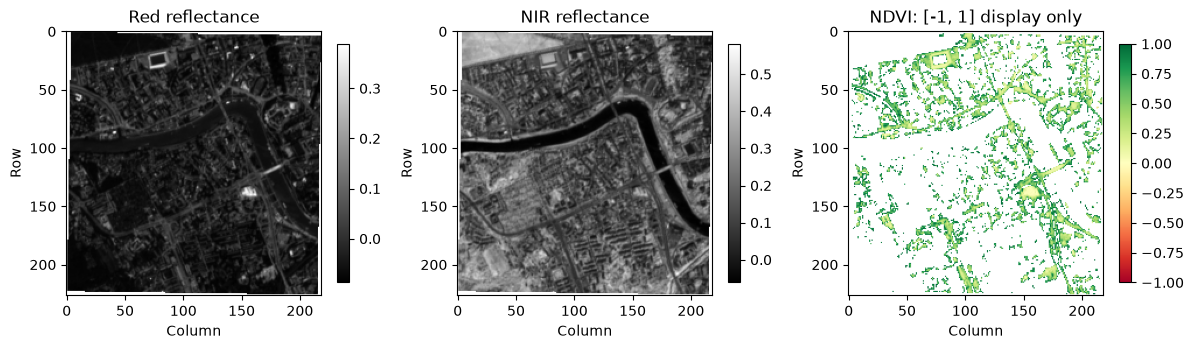

In [10]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt

main_config = json.loads((PROJECT / 'config' / 'krakow_aoi.json').read_text())
main_aoi_json = json.dumps({'crs': 'EPSG:4326', 'bbox': main_config['aoi_bbox']},
                           sort_keys=True, separators=(',', ':'))
paths = {}
if DB.is_file():
    with sqlite3.connect(f'{DB.as_uri()}?mode=ro', uri=True) as conn:
        names = {row[0] for row in conn.execute("SELECT name FROM sqlite_master WHERE type='table'")}
        if 'artifact_locations' in names:
            for band, path in conn.execute("""SELECT a.asset_key,l.local_path FROM subset_requests s
                JOIN assets a USING(asset_id) JOIN artifact_locations l ON l.artifact_id=s.latest_artifact_id
                WHERE l.status='available' AND s.aoi_json=?
                  AND a.collection=? AND a.item_id=? ORDER BY s.updated_at""",
                (main_aoi_json, main_config['collection'], main_config['item_id'])):
                paths[band] = Path(path)
if set(paths) != {'red','nir'} or not all(p.is_file() for p in paths.values()):
    print('Acquire both main-archive AOI subsets first; no download is performed by this cell.')
else:
    arrays = {}
    grids = {}
    for band, path in paths.items():
        with rasterio.open(path) as src:
            grids[band] = (src.crs, src.transform, src.shape)
            arrays[band] = src.read(1, masked=True).astype('float32') * src.scales[0] + src.offsets[0]
            print(band, src.shape, src.crs, 'scale:', src.scales[0], 'offset:', src.offsets[0])
    assert grids['red'] == grids['nir'], 'Choose the same AOI and aligned bands'
    red, nir = arrays['red'], arrays['nir']
    denominator = nir + red
    with np.errstate(divide='ignore', invalid='ignore'):
        ndvi = np.ma.masked_where(denominator <= 0, (nir-red) / denominator)
    inspected = ndvi.compressed()
    outside = int(np.count_nonzero((inspected < -1) | (inspected > 1)))
    print('Raw calibrated NDVI:', len(inspected), 'unmasked pixels;',
          'range:', float(inspected.min()), float(inspected.max()))
    print('Values outside [-1, 1]:', outside,
          '(masked for display only; original ndvi array retained)')
    fig, axes = plt.subplots(1,3,figsize=(12,4))
    for ax, values, title in zip(axes,[red,nir,ndvi],['Red reflectance','NIR reflectance','NDVI: [-1, 1] display only']):
        is_ndvi = title.startswith('NDVI')
        displayed = np.ma.masked_outside(values, -1, 1) if is_ndvi else values
        im = ax.imshow(displayed, cmap='RdYlGn' if is_ndvi else 'gray',
                       vmin=-1 if is_ndvi else None, vmax=1 if is_ndvi else None)
        ax.set_title(title); ax.set_xlabel('Column'); ax.set_ylabel('Row')
        fig.colorbar(im,ax=ax,shrink=0.65)
    plt.tight_layout()
    plt.show()


## Submission and interpretation

Submit student_schema.sql, your investigation_queries.sql, this notebook with
predictions/SQL results/explanations, and a small report:

```bash
python lab03_cli.py report --config config/krakow_aoi.json > lab03_report.json
```

For each required failure, state: symptom, query, observed rows, diagnosis, recovery,
and post-recovery evidence. A screenshot alone is not a diagnosis. Explain which
claims are protected by database constraints and which require checking bytes,
filesystem state or raster metadata.

Keep state/, data/, and cases/ out of Git. Successful offline checks do not claim
that a live request succeeded. If the provider/network is unavailable, retain that
failure evidence and complete the live acquisition later; no synthetic image is
substituted.

Sources: [Rasterio windowed reading/writing](https://rasterio.readthedocs.io/en/latest/topics/windowed-rw.html)
and [Earth Search metadata](https://github.com/Element84/earth-search/blob/main/README.md).

### Completed explanation

All required work is complete: the five-table schema, eight passing offline
check groups, main live B04/B08 acquisition and verified repeat, oversized-AOI
rejection, both isolated failure investigations and recoveries, and the
alternative-AOI identity demonstration. The notebook retains predictions, actual
before/after SQL results and explanations; lab03_report.json is the final main
archive report. lab03_investigation.md is a portable compact case report.

The main archive contains four ready requests and four available artifacts across
two AOIs of one scene; it retains six acquisition/verification attempts. The network
case retains four attempts and the missing-file case seven, including their
original failures. The supplied Python and checks are unchanged; the optional
notebook plot pins the main AOI and reports/masks out-of-range ratios for display. Runtime databases,
raster files, raw snapshots, case configurations and full logs remain under the
existing ignored state/, data/ and cases/ folders.

SQLite protects identities, references, lifecycle invariants and JSON structure.
Application verification protects claims about actual filesystem presence, size,
SHA-256, grid, calibration and AOI masking. Neither a successful database insert
nor a clean foreign_key_check can establish those physical properties on its own.


In [11]:
report_file = PROJECT / 'lab03_report.json'
if report_file.is_file():
    final_report = json.loads(report_file.read_text())
    print('Main archive:', len(final_report['subsets']), 'requests,',
          len(final_report['attempts']), 'attempts,',
          len(final_report['locations']), 'locations')
    print('Request states:', [s['status'] for s in final_report['subsets']])
    print('Location states:', [s['status'] for s in final_report['locations']])
show_query('main-final', 'foreign_key_check')
show_query('network-after', 'foreign_key_check')
show_query('missing-after', 'foreign_key_check')


Main archive: 4 requests, 6 attempts, 4 locations
Request states: ['ready', 'ready', 'ready', 'ready']
Location states: ['available', 'available', 'available', 'available']
Snapshot: main-final | Captured: 2026-10-25T17:00:25.672290Z
Query: foreign_key_check
[]
Snapshot: network-after | Captured: 2026-10-25T16:59:56.109060Z
Query: foreign_key_check
[]
Snapshot: missing-after | Captured: 2026-10-25T17:00:13.814172Z
Query: foreign_key_check
[]
